# Baseline Fraud Classifier

In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("creditcard.csv")
print(df.shape)
print(df.info())

(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

In [6]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

In [10]:
lazy_accuracy = (df["Class"] == 0).mean()
print(f"Accuracy of always predicting 'not fraud: {lazy_accuracy}")

Accuracy of always predicting 'not fraud: 0.9982725143693799


## Split + weighted logistic regression

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Class")
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]: print(name, len(part), f"fraud rate: {part.mean():.4%}")

train 170884 fraud rate: 0.1726%
val 56961 fraud rate: 0.1720%
test 56962 fraud rate: 0.1738%


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## PR curve, PR-AUC, threshold

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

val_proba = model.predict_proba(X_val)[:,1]
prec, rec, thr = precision_recall_curve(y_val, val_proba)
print(f"PR-AUC (average_precision): {average_precision_score(y_val, val_proba)}")
print(f"Random-guess baseline: {y_val.mean()}")

Matplotlib is building the font cache; this may take a moment.


PR-AUC (average_precision): 0.6857033653175553
Random-guess baseline: 0.0017204754130018785


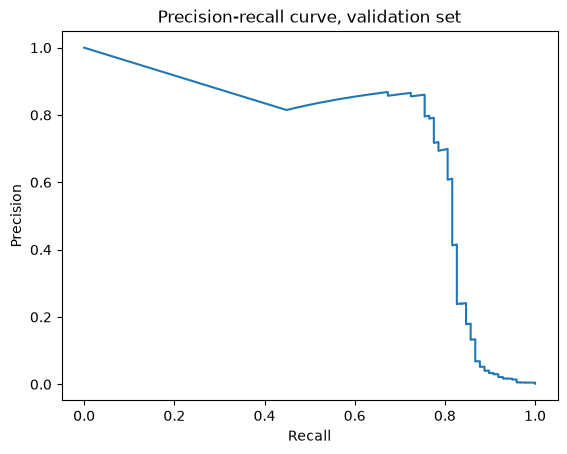

In [18]:
plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve, validation set")
plt.show()

In [20]:
from sklearn.metrics import confusion_matrix

COST_FN, COST_FP = 100, 5

thresholds = np.linspace(0.01, 0.99, 99)
costs =[]

for t in thresholds:
    pred = (val_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    costs.append(fn*COST_FN + fp*COST_FP)


best_t = thresholds[int(np.argmin(costs))]
print(f"Best threshold: {best_t}, validation cost: €{min(costs)}")

Best threshold: 0.98, validation cost: €2100


In [21]:
from sklearn.metrics import classification_report

test_proba = model.predict_proba(X_test)[:,1]
for t in [0.5, best_t]:
    pred = (test_proba >= t).astype(int)
    print(f"\nThreshold {t}")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))



Threshold 0.5
[[55553  1310]
 [    9    90]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56863
           1       0.06      0.91      0.12        99

    accuracy                           0.98     56962
   macro avg       0.53      0.94      0.55     56962
weighted avg       1.00      0.98      0.99     56962


Threshold 0.98
[[56792    71]
 [   14    85]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.54      0.86      0.67        99

    accuracy                           1.00     56962
   macro avg       0.77      0.93      0.83     56962
weighted avg       1.00      1.00      1.00     56962

